# Cardiovascular Regulation: ODE Simulation Framework

Mathematical model of baroreceptor-mediated blood pressure regulation with a pharmacological term.
Conceptually motivated by Ursino (1998) and Olufsen et al. (2006); simplified and linearised.

**State variables**
- P(t): mean arterial blood pressure (mmHg)
- S(t): sympathetic nervous system activity (dimensionless, relative to rest; not bounded)
- B(t): baroreceptor firing rate (dimensionless, relative to rest; not bounded)

**ODE system**

$$\frac{dP}{dt} = -\lambda (P - P_{set}) + \alpha S - d\,(P - P_{set})$$
$$\frac{dS}{dt} = \beta (S_{set} - B) - \gamma (S - S_{rest})$$
$$\frac{dB}{dt} = k (P - P_{set}) - \delta (B - B_{rest})$$

All parameters are in the first code cell. Run with **Kernel → Restart & Run All**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.linalg import eigvals

# ─────────────────────────────────────────────────────────────────────────────
# BASELINE PARAMETERS  (edit values here, do not touch the equations below)
# ─────────────────────────────────────────────────────────────────────────────

PARAMS = {
    "Pset":  100.0,  # pressure set-point                              (mmHg)
    "Sset":  0.5,    # sympathetic level the baroreflex pulls toward   (dimensionless)
    "Srest": 0.5,    # resting sympathetic activity                    (dimensionless)
    "Brest": 0.5,    # resting baroreceptor firing                     (dimensionless)
    "lam":   0.08,   # pressure relaxation rate                        (min^-1)
    "alpha": 0.6,    # sympathetic effect on pressure                  (mmHg min^-1 per unit S)
    "beta":  1.0,    # baroreceptor inhibition of sympathetic activity (min^-1)
    "gamma": 0.8,    # sympathetic decay rate                          (min^-1)
    "delta": 0.5,    # baroreceptor decay rate                         (min^-1)
    "k":     0.08,   # baroreceptor sensitivity (scenarios override)   (mmHg^-1 min^-1)
    "d":     0.0,    # drug term (scenarios override)                  (min^-1)
}

# ─────────────────────────────────────────────────────────────────────────────
# SCENARIOS  (each entry overrides only the parameters that differ from PARAMS)
# ─────────────────────────────────────────────────────────────────────────────

SCENARIOS = [
    {"name": "Healthy",                   "k": 0.08, "d": 0.00},
    {"name": "Hypertension",              "k": 0.02, "d": 0.00},
    {"name": "Hypertension + Low Dose",   "k": 0.02, "d": 0.02},
    {"name": "Hypertension + Std Dose",   "k": 0.02, "d": 0.05},
]

# Initial conditions (same for all scenarios): [P(0), S(0), B(0)]
Y0 = [80.0, 0.6, 0.5]

# Simulation time (minutes)
T_SPAN = (0, 60)
T_EVAL = np.linspace(0, 60, 1201)

In [2]:
# ─────────────────────────────────────────────────────────────────────────────
# ODE SYSTEM
# ─────────────────────────────────────────────────────────────────────────────
def ode_system(t, y, p):
    """Right-hand side of the coupled ODE system. y = [P, S, B]."""
    P, S, B = y
    dP_dt = -p["lam"] * (P - p["Pset"]) + p["alpha"] * S - p["d"] * (P - p["Pset"])
    dS_dt = p["beta"] * (p["Sset"] - B) - p["gamma"] * (S - p["Srest"])
    dB_dt = p["k"] * (P - p["Pset"]) - p["delta"] * (B - p["Brest"])
    return [dP_dt, dS_dt, dB_dt]


def build_params(overrides):
    """Merge scenario overrides into a copy of PARAMS."""
    p = PARAMS.copy()
    p.update({key: v for key, v in overrides.items() if key != "name"})
    return p


def run_scenario(scenario, rtol=1e-8, atol=1e-10):
    """Solve the ODE for a given scenario dict."""
    p = build_params(scenario)
    return solve_ivp(ode_system, T_SPAN, Y0, method="RK45", t_eval=T_EVAL,
                     args=(p,), rtol=rtol, atol=atol)


results = {s["name"]: run_scenario(s) for s in SCENARIOS}
print("All scenarios solved successfully.")

All scenarios solved successfully.


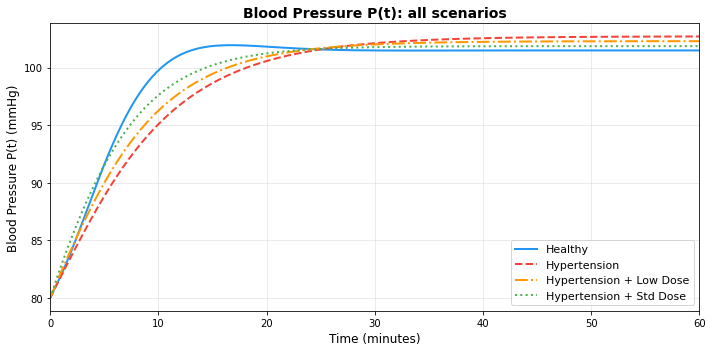

Saved: plot_P_timeseries.png


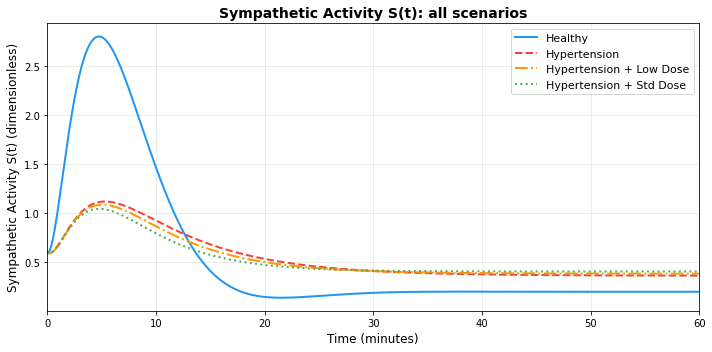

Saved: plot_S_timeseries.png


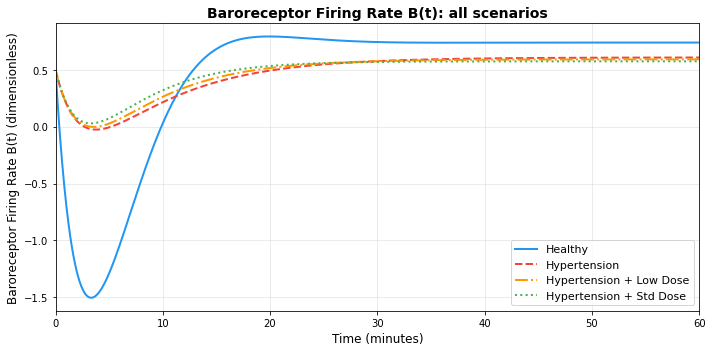

Saved: plot_B_timeseries.png


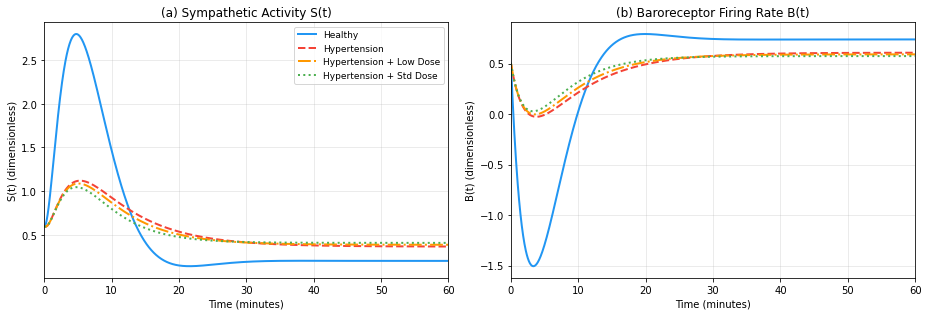

Saved: plot_SB_panels.png


In [3]:
# ─────────────────────────────────────────────────────────────────────────────
# TIME-SERIES PLOTS
# ─────────────────────────────────────────────────────────────────────────────

COLORS    = ["#2196F3", "#F44336", "#FF9800", "#4CAF50"]
LINESTYLE = ["-", "--", "-.", ":"]

var_labels = [
    (0, "Blood Pressure P(t)",           "mmHg",          "P"),
    (1, "Sympathetic Activity S(t)",     "dimensionless", "S"),
    (2, "Baroreceptor Firing Rate B(t)", "dimensionless", "B"),
]

for var_idx, var_name, var_unit, short in var_labels:
    fig, ax = plt.subplots(figsize=(10, 5))
    for i, scenario in enumerate(SCENARIOS):
        sol = results[scenario["name"]]
        ax.plot(sol.t, sol.y[var_idx], label=scenario["name"], color=COLORS[i],
                linestyle=LINESTYLE[i], linewidth=2.0)
    ax.set_xlabel("Time (minutes)", fontsize=12)
    ax.set_ylabel(f"{var_name} ({var_unit})", fontsize=12)
    ax.set_title(f"{var_name}: all scenarios", fontsize=14, fontweight="bold")
    ax.legend(fontsize=11); ax.grid(True, alpha=0.3); ax.set_xlim(0, 60)
    plt.tight_layout()
    plt.savefig(f"plot_{short}_timeseries.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: plot_{short}_timeseries.png")

# Two-panel figure for the report: (a) S(t), (b) B(t)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (var_idx, var_name, var_unit, short) in zip(axes, var_labels[1:]):
    for i, scenario in enumerate(SCENARIOS):
        sol = results[scenario["name"]]
        ax.plot(sol.t, sol.y[var_idx], label=scenario["name"], color=COLORS[i],
                linestyle=LINESTYLE[i], linewidth=2.0)
    ax.set_xlabel("Time (minutes)"); ax.set_ylabel(f"{short}(t) ({var_unit})")
    ax.set_title(("(a) " if short == "S" else "(b) ") + var_name)
    ax.grid(True, alpha=0.3); ax.set_xlim(0, 60)
axes[0].legend(fontsize=9)
plt.tight_layout()
plt.savefig("plot_SB_panels.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: plot_SB_panels.png")

In [4]:
# ─────────────────────────────────────────────────────────────────────────────
# EQUILIBRIUM & STABILITY ANALYSIS
# ─────────────────────────────────────────────────────────────────────────────

def analytical_jacobian(y, p):
    """Jacobian of the ODE system. The model is linear, so it does not depend on y.
    Rows = [dP/dt, dS/dt, dB/dt]; columns = [P, S, B]."""
    return np.array([
        [-(p["lam"] + p["d"]),  p["alpha"],  0.0         ],
        [0.0,                  -p["gamma"], -p["beta"]   ],
        [p["k"],                0.0,        -p["delta"]  ],
    ])


def find_equilibrium(p):
    """Exact equilibrium of the linear system  dy/dt = A y + c = 0  ->  y* = -A^-1 c."""
    A = analytical_jacobian(None, p)
    c = np.array(ode_system(0, [0.0, 0.0, 0.0], p))   # value of the right-hand side at y = 0
    eq = np.linalg.solve(A, -c)
    residual = np.max(np.abs(ode_system(0, eq, p)))
    if residual > 1e-10:
        print(f"  WARNING: equilibrium residual = {residual:.2e}")
    return eq


def closed_form_P(p):
    """Closed-form equilibrium pressure (derived by hand; used as an independent check)."""
    num = p["alpha"] * (p["Srest"] + (p["beta"] / p["gamma"]) * (p["Sset"] - p["Brest"]))
    den = p["lam"] + p["d"] + p["alpha"] * p["beta"] * p["k"] / (p["gamma"] * p["delta"])
    return p["Pset"] + num / den


print("=" * 72)
print(f"{'EQUILIBRIUM & STABILITY ANALYSIS':^72}")
print("=" * 72)

stability_data = []
for scenario in SCENARIOS:
    p = build_params(scenario)
    name = scenario["name"]
    eq = find_equilibrium(p)
    ev = eigvals(analytical_jacobian(eq, p))
    stable = all(np.real(e) < 0 for e in ev)
    stability_data.append({"name": name, "eq": eq, "eigenvalues": ev, "stable": stable})

    print(f"\nScenario: {name}")
    print(f"  Equilibrium  ->  P* = {eq[0]:.2f} mmHg,  S* = {eq[1]:.4f},  B* = {eq[2]:.4f}")
    print(f"  Closed-form P* = {closed_form_P(p):.2f} mmHg  (should match)")
    for j, e in enumerate(ev):
        extra = ""
        if abs(e.imag) > 1e-9 and e.imag > 0:
            extra = f"  oscillation period = {2*np.pi/abs(e.imag):.1f} min"
        print(f"    eigenvalue {j+1} = {e:.4f}{extra}")
    print(f"  Stability:  [{'STABLE' if stable else 'UNSTABLE'}]")
    print("-" * 72)

                    EQUILIBRIUM & STABILITY ANALYSIS                    

Scenario: Healthy
  Equilibrium  ->  P* = 101.50 mmHg,  S* = 0.2000,  B* = 0.7400
  Closed-form P* = 101.50 mmHg  (should match)
    eigenvalue 1 = -0.2245+0.1885j  oscillation period = 33.3 min
    eigenvalue 2 = -0.2245-0.1885j
    eigenvalue 3 = -0.9309+0.0000j
  Stability:  [STABLE]
------------------------------------------------------------------------

Scenario: Hypertension
  Equilibrium  ->  P* = 102.73 mmHg,  S* = 0.3636,  B* = 0.6091
  Closed-form P* = 102.73 mmHg  (should match)
    eigenvalue 1 = -0.1280+0.0000j
    eigenvalue 2 = -0.4066+0.0000j
    eigenvalue 3 = -0.8454+0.0000j
  Stability:  [STABLE]
------------------------------------------------------------------------

Scenario: Hypertension + Low Dose
  Equilibrium  ->  P* = 102.31 mmHg,  S* = 0.3846,  B* = 0.5923
  Closed-form P* = 102.31 mmHg  (should match)
    eigenvalue 1 = -0.1536+0.0000j
    eigenvalue 2 = -0.4000+0.0000j
    eigenvalu

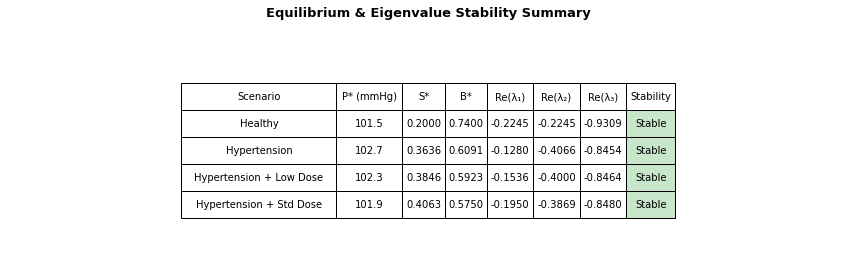

Saved: plot_stability_table.png


In [5]:
# ─────────────────────────────────────────────────────────────────────────────
# STABILITY SUMMARY TABLE (visual)
# ─────────────────────────────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(12, 4))
ax.axis("off")

col_headers = ["Scenario", "P* (mmHg)", "S*", "B*", "Re(λ₁)", "Re(λ₂)", "Re(λ₃)", "Stability"]
rows = []
for dd in stability_data:
    ev = dd["eigenvalues"]
    rows.append([
        dd["name"],
        f"{dd['eq'][0]:.1f}", f"{dd['eq'][1]:.4f}", f"{dd['eq'][2]:.4f}",
        f"{np.real(ev[0]):.4f}", f"{np.real(ev[1]):.4f}", f"{np.real(ev[2]):.4f}",
        "Stable" if dd["stable"] else "UNSTABLE",
    ])

table = ax.table(cellText=rows, colLabels=col_headers, loc="center", cellLoc="center")
table.auto_set_font_size(False)
table.set_fontsize(10)
table.auto_set_column_width(col=list(range(len(col_headers))))
table.scale(1.0, 2.0)

for row_idx, dd in enumerate(stability_data):
    table[row_idx + 1, 7].set_facecolor("#C8E6C9" if dd["stable"] else "#FFCDD2")

ax.set_title("Equilibrium & Eigenvalue Stability Summary", fontsize=13, fontweight="bold", pad=12)
plt.tight_layout()
plt.savefig("plot_stability_table.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: plot_stability_table.png")

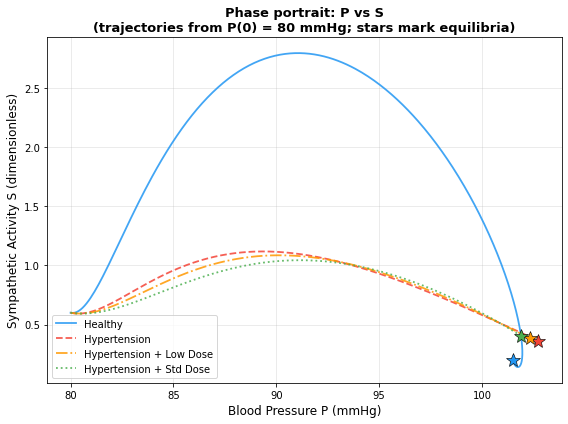

Saved: plot_phase_portrait.png


In [6]:
# ─────────────────────────────────────────────────────────────────────────────
# PHASE PORTRAIT: P vs S  (B held at equilibrium value per scenario)
# ─────────────────────────────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(8, 6))
for i, scenario in enumerate(SCENARIOS):
    sol = results[scenario["name"]]
    dd = stability_data[i]
    ax.plot(sol.y[0], sol.y[1], label=scenario["name"], color=COLORS[i],
            linestyle=LINESTYLE[i], linewidth=1.8, alpha=0.85)
    ax.plot(dd["eq"][0], dd["eq"][1], marker="*", markersize=14, color=COLORS[i],
            markeredgecolor="black", markeredgewidth=0.6)

ax.set_xlabel("Blood Pressure P (mmHg)", fontsize=12)
ax.set_ylabel("Sympathetic Activity S (dimensionless)", fontsize=12)
ax.set_title("Phase portrait: P vs S\n(trajectories from P(0) = 80 mmHg; stars mark equilibria)",
             fontsize=13, fontweight="bold")
ax.legend(fontsize=10); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("plot_phase_portrait.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: plot_phase_portrait.png")

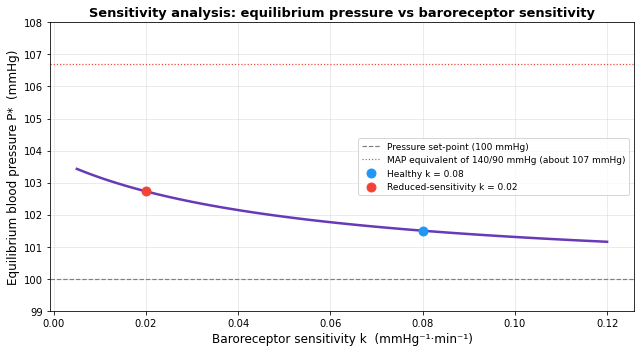

Saved: plot_sensitivity_k.png


In [7]:
# ─────────────────────────────────────────────────────────────────────────────
# SENSITIVITY ANALYSIS: equilibrium P* vs baroreceptor sensitivity k
# ─────────────────────────────────────────────────────────────────────────────

k_values = np.linspace(0.005, 0.12, 80)
eq_P_values = []
for k_val in k_values:
    p_sens = PARAMS.copy()
    p_sens["k"] = k_val
    p_sens["d"] = 0.0
    eq_P_values.append(find_equilibrium(p_sens)[0])

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(k_values, eq_P_values, color="#673AB7", linewidth=2.5)
ax.axhline(100, color="grey", linestyle="--", linewidth=1.2, label="Pressure set-point (100 mmHg)")
ax.axhline(106.7, color="#F44336", linestyle=":", linewidth=1.2,
           label="MAP equivalent of 140/90 mmHg (about 107 mmHg)")

for k_mark, label_mark, col_mark in [(0.08, "Healthy k", "#2196F3"),
                                     (0.02, "Reduced-sensitivity k", "#F44336")]:
    p_mark = PARAMS.copy(); p_mark["k"] = k_mark
    ax.scatter([k_mark], [find_equilibrium(p_mark)[0]], zorder=5, s=80, color=col_mark,
               label=f"{label_mark} = {k_mark}")

ax.set_ylim(99, 108)
ax.set_xlabel("Baroreceptor sensitivity k  (mmHg⁻¹·min⁻¹)", fontsize=12)
ax.set_ylabel("Equilibrium blood pressure P*  (mmHg)", fontsize=12)
ax.set_title("Sensitivity analysis: equilibrium pressure vs baroreceptor sensitivity",
             fontsize=13, fontweight="bold")
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("plot_sensitivity_k.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: plot_sensitivity_k.png")

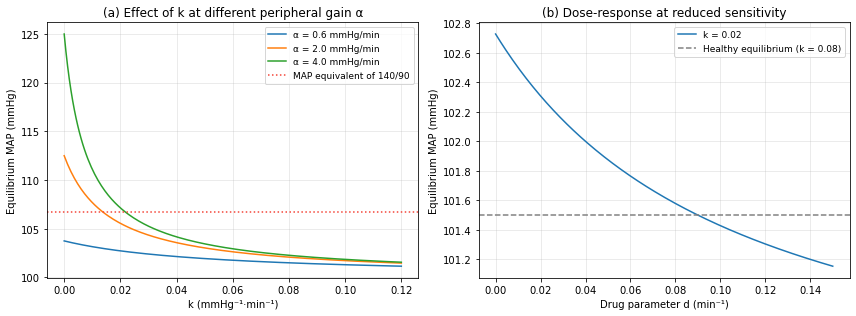

Saved: plot_extended_sensitivity.png


In [8]:
# ─────────────────────────────────────────────────────────────────────────────
# EXTENDED SENSITIVITY ANALYSIS: peripheral gain alpha and drug dose
# ─────────────────────────────────────────────────────────────────────────────


fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

k_grid = np.linspace(0.0, 0.12, 200)
for a in (0.6, 2.0, 4.0):
    vals = []
    for kv in k_grid:
        pp = PARAMS.copy(); pp["k"] = kv; pp["alpha"] = a
        vals.append(closed_form_P(pp))
    axes[0].plot(k_grid, vals, label=f"α = {a} mmHg/min")
axes[0].axhline(106.7, color="#F44336", linestyle=":", label="MAP equivalent of 140/90")
axes[0].set_xlabel("k (mmHg⁻¹·min⁻¹)"); axes[0].set_ylabel("Equilibrium MAP (mmHg)")
axes[0].set_title("(a) Effect of k at different peripheral gain α")
axes[0].legend(fontsize=9); axes[0].grid(True, alpha=0.3)

d_grid = np.linspace(0.0, 0.15, 200)
vals = []
for dv in d_grid:
    pp = PARAMS.copy(); pp["k"] = 0.02; pp["d"] = dv
    vals.append(closed_form_P(pp))
axes[1].plot(d_grid, vals, label="k = 0.02")
pp = PARAMS.copy(); pp["k"] = 0.08
axes[1].axhline(closed_form_P(pp), color="grey", linestyle="--", label="Healthy equilibrium (k = 0.08)")
axes[1].set_xlabel("Drug parameter d (min⁻¹)"); axes[1].set_ylabel("Equilibrium MAP (mmHg)")
axes[1].set_title("(b) Dose-response at reduced sensitivity")
axes[1].legend(fontsize=9); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("plot_extended_sensitivity.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: plot_extended_sensitivity.png")

In [9]:
# ─────────────────────────────────────────────────────────────────────────────
# Validation Checks
# ─────────────────────────────────────────────────────────────────────────────



print("CHECK 1: numerical vs closed-form equilibrium pressure")
for scenario in SCENARIOS:
    p = build_params(scenario)
    diff = abs(find_equilibrium(p)[0] - closed_form_P(p))
    print(f"  {scenario['name']:<26} difference = {diff:.2e} mmHg")

print("\nCHECK 2: does the simulation end at the equilibrium?")
for i, scenario in enumerate(SCENARIOS):
    final = results[scenario["name"]].y[:, -1]
    err = np.max(np.abs(final - stability_data[i]["eq"]))
    print(f"  {scenario['name']:<26} max |final state - equilibrium| = {err:.2e}")

print("\nCHECK 3: tighter solver tolerances give the same curves?")
for scenario in SCENARIOS:
    tight = run_scenario(scenario, rtol=1e-11, atol=1e-13)
    err = np.max(np.abs(tight.y[0] - results[scenario["name"]].y[0]))
    print(f"  {scenario['name']:<26} max difference in P(t) = {err:.2e} mmHg")

print("\nCHECK 4: where does stability break? (d = 0)")
for kv in (0.08, 1.0, 1.2):
    p = PARAMS.copy(); p["k"] = kv; p["d"] = 0.0
    ev = eigvals(analytical_jacobian(None, p))
    worst = np.max(np.real(ev))
    print(f"  k = {kv:<5} largest real part = {worst:+.4f}  ->  {'STABLE' if worst < 0 else 'UNSTABLE'}")

CHECK 1: numerical vs closed-form equilibrium pressure
  Healthy                    difference = 1.42e-14 mmHg
  Hypertension               difference = 0.00e+00 mmHg
  Hypertension + Low Dose    difference = 1.42e-14 mmHg
  Hypertension + Std Dose    difference = 0.00e+00 mmHg

CHECK 2: does the simulation end at the equilibrium?
  Healthy                    max |final state - equilibrium| = 2.31e-05
  Hypertension               max |final state - equilibrium| = 1.29e-02
  Hypertension + Low Dose    max |final state - equilibrium| = 2.85e-03
  Hypertension + Std Dose    max |final state - equilibrium| = 2.61e-04

CHECK 3: tighter solver tolerances give the same curves?
  Healthy                    max difference in P(t) = 1.90e-08 mmHg
  Hypertension               max difference in P(t) = 7.51e-08 mmHg
  Hypertension + Low Dose    max difference in P(t) = 7.05e-08 mmHg
  Hypertension + Std Dose    max difference in P(t) = 6.68e-08 mmHg

CHECK 4: where does stability break? (d = 0)
  k

In [10]:
# ─────────────────────────────────────────────────────────────────────────────
# Every number the report quotes
# ─────────────────────────────────────────────────────────────────────────────


from scipy.optimize import brentq

print("NUMBERS QUOTED IN THE REPORT")
print("=" * 72)
p_hyp = build_params(SCENARIOS[1])
print(f"Initial slope of P (hypertension): "
      f"{-p_hyp['lam']*(Y0[0]-p_hyp['Pset']) + p_hyp['alpha']*Y0[1]:.2f} mmHg/min")

for i, scenario in enumerate(SCENARIOS):
    sol = results[scenario["name"]]
    t = sol.t; P, S, B = sol.y
    eq = stability_data[i]["eq"]
    tol = 0.02 * abs(Y0[0] - eq[0])
    t_settle = t[np.where(np.abs(P - eq[0]) > tol)[0][-1]]
    print(f"\n{scenario['name']}")
    print(f"  P at 10 min = {P[np.argmin(abs(t-10))]:.1f}   P at 20 min = {P[np.argmin(abs(t-20))]:.1f}")
    print(f"  Peak P = {P.max():.2f} mmHg at t = {t[P.argmax()]:.1f} min  (above P*: {P.max()-eq[0]:.2f})")
    print(f"  Peak S = {S.max():.2f} at t = {t[S.argmax()]:.1f} min;  lowest B = {B.min():.2f} at t = {t[B.argmin()]:.1f} min")
    print(f"  Time to come within 2% of the initial gap = {t_settle:.1f} min")

print("\nGap between hypertension and healthy equilibrium, and share closed by the drug")
P_h_eq, P_hyp_eq = stability_data[0]["eq"][0], stability_data[1]["eq"][0]
print(f"  gap = {P_hyp_eq - P_h_eq:.3f} mmHg")
for i in (2, 3):
    closed = (P_hyp_eq - stability_data[i]["eq"][0]) / (P_hyp_eq - P_h_eq)
    print(f"  {SCENARIOS[i]['name']}: closes {100*closed:.0f}% of the gap")

print(f"\nS* increase, hypertension vs healthy: "
      f"{100*(stability_data[1]['eq'][1]/stability_data[0]['eq'][1]-1):.0f}%")

def P_of_d(dv):
    p = build_params(SCENARIOS[1]); p["d"] = dv
    return closed_form_P(p) - P_h_eq
print(f"Drug value that fully restores healthy pressure at k = 0.02: d = {brentq(P_of_d, 0, 1):.3f}")

def P_of_k(kv):
    p = build_params(SCENARIOS[3]); p["d"] = 0.0; p["k"] = kv
    return closed_form_P(p) - stability_data[3]["eq"][0]
print(f"k that gives the same pressure as d = 0.05 at k = 0.02: k = {brentq(P_of_k, 0.02, 1):.3f}")

p0 = PARAMS.copy(); p0["k"] = 0.0
print(f"Maximum equilibrium pressure with no baroreflex (k = 0): {closed_form_P(p0):.2f} mmHg")

print("\nEquilibrium pressure for different peripheral gain alpha")
for a in (0.6, 2.0, 4.0):
    row = []
    for kv in (0.08, 0.02):
        pp = PARAMS.copy(); pp["alpha"] = a; pp["k"] = kv
        row.append(closed_form_P(pp))
    print(f"  alpha = {a}: k = 0.08 -> {row[0]:.1f},  k = 0.02 -> {row[1]:.1f} mmHg")

a2 = PARAMS["lam"] + PARAMS["gamma"] + PARAMS["delta"]
a1 = PARAMS["lam"]*PARAMS["gamma"] + PARAMS["lam"]*PARAMS["delta"] + PARAMS["gamma"]*PARAMS["delta"]
k_crit = (a2*a1 - PARAMS["lam"]*PARAMS["gamma"]*PARAMS["delta"]) / (PARAMS["alpha"]*PARAMS["beta"])
print(f"\nRouth-Hurwitz critical k (d = 0): {k_crit:.3f};  oscillation period at that point = {2*np.pi/np.sqrt(a1):.1f} min")

NUMBERS QUOTED IN THE REPORT
Initial slope of P (hypertension): 1.96 mmHg/min

Healthy
  P at 10 min = 99.8   P at 20 min = 101.8
  Peak P = 101.96 mmHg at t = 16.7 min  (above P*: 0.46)
  Peak S = 2.80 at t = 4.8 min;  lowest B = -1.50 at t = 3.3 min
  Time to come within 2% of the initial gap = 18.0 min

Hypertension
  P at 10 min = 95.1   P at 20 min = 100.6
  Peak P = 102.71 mmHg at t = 60.0 min  (above P*: -0.01)
  Peak S = 1.12 at t = 5.4 min;  lowest B = -0.03 at t = 3.8 min
  Time to come within 2% of the initial gap = 32.1 min

Hypertension + Low Dose
  P at 10 min = 96.3   P at 20 min = 101.0
  Peak P = 102.30 mmHg at t = 60.0 min  (above P*: -0.00)
  Peak S = 1.09 at t = 5.1 min;  lowest B = -0.00 at t = 3.6 min
  Time to come within 2% of the initial gap = 27.1 min

Hypertension + Std Dose
  P at 10 min = 97.6   P at 20 min = 101.2
  Peak P = 101.87 mmHg at t = 60.0 min  (above P*: -0.00)
  Peak S = 1.04 at t = 4.8 min;  lowest B = 0.03 at t = 3.3 min
  Time to come within 

## How to add a scenario
Add one line to the `SCENARIOS` list in the first code cell, for example:

`{"name": "My New Scenario", "k": 0.05, "d": 0.03},`

(The time-series plots use four colours. To add a fifth scenario, also add a colour to `COLORS` and a style to `LINESTYLE` in the plotting cell.)

## How to change a baseline parameter
Edit the value in `PARAMS` in the first code cell, e.g. change `"alpha": 0.6` to `"alpha": 1.0`. Every scenario that does not override that parameter picks it up automatically.

## Output files
| File | Contents |
|---|---|
| plot_P_timeseries.png | Blood pressure over time, all 4 scenarios |
| plot_S_timeseries.png | Sympathetic activity over time |
| plot_B_timeseries.png | Baroreceptor firing rate over time |
| plot_SB_panels.png | S(t) and B(t) side by side |
| plot_stability_table.png | Equilibria, eigenvalues and stability |
| plot_phase_portrait.png | P vs S phase portrait with equilibria |
| plot_sensitivity_k.png | Equilibrium pressure vs baroreceptor sensitivity k |
| plot_extended_sensitivity.png | Effect of peripheral gain α and drug dose d |